# Phase 2 Submission
## by Group 1

Github link: https://github.com/geilahtabanao/CSC930M-Project1

## 1. Setup

Import the necessary libraries

In [8]:
import os, csv, time, re, glob, gc, json, math
from concurrent.futures import ThreadPoolExecutor
from functools import partial
from typing import Optional, Sequence
import unicodedata

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn, Tensor
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from PIL import Image
from tqdm.auto import tqdm
import easyocr
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

os.environ["TOKENIZERS_PARALLELISM"] = "false"

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda:1"
print("torch", torch.__version__, "| device:", device)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

torch 2.14.1+cu126 | device: cuda:1


## 2. Data

Load the 224x224 images and prepare them in numpy files

In [12]:
def load_or_cache(split, folder, csv_path, cache_dir="cache", size=(224, 224), batch=1000, workers=8):
    os.makedirs(cache_dir, exist_ok=True)
    xp = os.path.join(cache_dir, f"X_{split}_{size[0]}.npy")
    yp = os.path.join(cache_dir, f"y_{split}_{size[0]}.npy")

    if os.path.exists(xp) and os.path.exists(yp):
        return np.load(xp), np.load(yp)

    df = pd.read_csv(csv_path, usecols=["filename", "category_id"])
    files = df["filename"].astype(str).values
    y = df["category_id"].values.astype(int)

    def read(f):
        path = os.path.join(folder, f)
        img = cv2.imread(path)

        if img is None:
            raise ValueError(f"Could not read image: {path}")

        return cv2.resize(img, size, interpolation=cv2.INTER_AREA).ravel()

    X = np.empty((len(files), size[0] * size[1] * 3), np.uint8)
    with ThreadPoolExecutor(workers) as ex:
        for i in range(0, len(files), batch):
            X[i:i + batch] = list(ex.map(read, files[i:i + batch]))

    np.save(xp, X)
    np.save(yp, y)
    return X, y

In [13]:
folder = "dataset_updated/224x224"

X_train, y_train = load_or_cache("train", folder, "dataset_updated/train/listings_train.csv")
X_val, y_val = load_or_cache("val", folder, "dataset_updated/validation/listings_val.csv")
X_test, y_test = load_or_cache("test", folder, "dataset_updated/test/listings_test.csv")

print(X_train.shape, X_val.shape, X_test.shape)

classes = np.unique(np.concatenate([y_train, y_val, y_test]))
y_train, y_val, y_test = (np.searchsorted(classes, y).astype(np.int64) for y in (y_train, y_val, y_test))
num_classes = len(classes)
print("num_classes:", num_classes)

(45593, 150528) (5700, 150528) (5700, 150528)
num_classes: 30


Convert the numpy files into PyTorch tensors. The mean and standard deviation used are from ImageNet. Image shifting for data augmentation was placed as on option in the Arrayloader to be implemented since other augmentations can severely distort what a book cover and its text can look like. 

In [7]:
mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)

std  = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)

def prep(xb, augment=False):
    x = torch.from_numpy(np.ascontiguousarray(xb)).to(device).float().div(255)
    x = x.view(-1, 224, 224, 3).permute(0, 3, 1, 2).flip(1) 
    if augment:
        pad = 16
        x = nn.functional.pad(x, (pad, pad, pad, pad), mode="reflect")
        i, j = np.random.randint(0, 2 * pad + 1, size=2)      
        x = x[:, :, i:i + 224, j:j + 224]
    return (x - mean) / std

class ArrayLoader:
    def __init__(self, X, y, batch_size=64, shuffle=False, augment=False):
        self.X, self.y, self.batch_size = X, y, batch_size
        self.shuffle, self.augment = shuffle, augment

    def __len__(self):
        return math.ceil(len(self.X) / self.batch_size)

    def __iter__(self):
        idx = np.random.permutation(len(self.X)) if self.shuffle else np.arange(len(self.X))
        for i in range(0, len(idx), self.batch_size):
            b = np.sort(idx[i:i + self.batch_size])
            yield prep(self.X[b], augment=self.augment), torch.from_numpy(self.y[b]).to(device)

Apply the function to the train, validation, and testing set. The training set was not included here because batch_size was considered for hyperparameter tuning

In [8]:
val_loader   = ArrayLoader(X_val,   y_val,   batch_size=256)

test_loader  = ArrayLoader(X_test,  y_test,  batch_size=256)

## 3. Model

## Utilities

The following functions are needed for the construction of the efficientnet structure model:

In [14]:
def pad(kernel_size, dilation=1) -> int:
    padding = (kernel_size - 1) // 2 * dilation
    return padding

def _make_divisible(value: float, divisor=8) -> int:
    new_value = max(divisor, int(value + divisor / 2) // divisor * divisor)
    if new_value < 0.9 * value:
        new_value += divisor
    return new_value

def round_repeats(num_repeats: int, depth_mult: float) -> int:
    if depth_mult == 1.0:
        return num_repeats
    return int(math.ceil(num_repeats * depth_mult))

def round_filters(filters: int, width_mult: float) -> int:
    if width_mult == 1.0:
        return filters
    return int(_make_divisible(filters * width_mult))

In [ ]:
def _stochastic_depth(x: Tensor, p: float, mode: str, training: bool = True) -> Tensor:
    assert 0.0 < p < 1.0, f"drop probability has to be between 0 and 1, but got {p}"
    assert mode in ["batch", "row"], f"mode has to be either 'batch' or 'row', but got {mode}"
    if not training or p == 0.0:
        return x

    survival_rate = 1.0 - p
    size = [x.shape[0]] + [1] * (x.ndim - 1)

    noise = torch.empty(size, dtype=x.dtype, device=x.device)
    noise = noise.bernoulli_(survival_rate)
    if survival_rate > 0.0:
        noise.div_(survival_rate)
    return x * noise

class StochasticDepth(nn.Module):
    def __init__(self, p: float, mode: str) -> None:
        super().__init__()
        self.p = p
        self.mode = mode

    def forward(self, x: Tensor) -> Tensor:
        return _stochastic_depth(x, self.p, self.mode, self.training)

EfficientNet structures can have chunky coding blocks. The add_to function just ensures that we can create the efficientnet network despite the coding limitations

In [11]:
def add_to(cls):
    def deco(fn):
        setattr(cls, fn.__name__, fn)
        return fn
    return deco

### Channel Calibration Modules

Squeeze Excitation is the default Channel Calibration Module for EfficientNet CNNs. It calibrates the importance of each feature in the whole feature map. It uses a sigmoid function for its activation to say whether something is important or not.

In [17]:
class SqueezeExcitation(torch.nn.Module):

    def __init__(self, in_channels: int, squeeze_channels: int) -> None:
        super().__init__()
        self.block = nn.Sequential(nn.AdaptiveAvgPool2d(1),
                                   nn.Conv2d(in_channels, squeeze_channels, 1),
                                   nn.SiLU(inplace=True),
                                   nn.Conv2d(squeeze_channels, in_channels, 1),
                                   nn.Sigmoid())

    def forward(self, x: Tensor) -> Tensor:
        return x * self.block(x)

Higurachi et al. (2024) mentioned that title positions prove to have a positive effect on the identification of genre. However, positional information tends to get lost on Squeeze Excitation. Coordinate Attention was built on improving the Squeeze Excitation since  where it considers positional information while performing the attention calibration in the feature maps, so it should prove helpful for book cover generalization.

In [18]:
class CoordAtt(nn.Module):
    def __init__(self, channels: int, reduction: int = 32) -> None:
        super().__init__()
        mid = max(8, channels // reduction)
        self.conv1 = nn.Conv2d(channels, mid, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid)
        self.act = nn.SiLU(inplace=True)
        self.conv_h = nn.Conv2d(mid, channels, 1)
        self.conv_w = nn.Conv2d(mid, channels, 1)
        self.reset_identity()

    def reset_identity(self) -> None:
        for m in (self.conv_h, self.conv_w):
            nn.init.zeros_(m.weight)
            nn.init.zeros_(m.bias)

The forward definition just completes the Coordinate Attention Class by performing the attention calibration with positional information through the double sigmoid function where one determines the vertical position and the other one determines the horizontal position. The SECoordAtt class is a modification to use the Coordinate Attention layered on top of the Squeeze Excitation to read the SE-trained weights from previous blocks before performing Coordinate Attention to maintain positional information.

In [19]:
@add_to(CoordAtt)
def forward(self, x: Tensor) -> Tensor:
    _, _, h, w = x.shape
    x_h = x.mean(dim=3, keepdim=True)                       
    x_w = x.mean(dim=2, keepdim=True).transpose(2, 3)       
    y = self.act(self.bn1(self.conv1(torch.cat([x_h, x_w], dim=2))))
    y_h, y_w = torch.split(y, [h, w], dim=2)
    a_h = 2 * torch.sigmoid(self.conv_h(y_h))                        
    a_w = 2 * torch.sigmoid(self.conv_w(y_w.transpose(2, 3)))        
    return x * a_h * a_w

class SECoordAtt(nn.Module):
    def __init__(self, channels, squeeze_channels):
        super().__init__()
        self.se = SqueezeExcitation(channels, squeeze_channels)
        self.coord = CoordAtt(channels)

    def forward(self, x):
        return self.coord(self.se(x))

### Color Feature Module

Colors often play a part in setting up the mood or conveying an idea, especially in books for their genre (Brian Kenji Iwana et al., 2016). Color stats computes the summary statistics for RGB: 3 means (one of R, G, and B in RGB), 3 standard deviations similar to means, 24 histogram values resulting from the 8 bins per each histogram of each RGB component)

In [20]:
class ColorStats(nn.Module):
    def __init__(self, bins: int = 8, size: int = 32) -> None:
        super().__init__()
        self.size = size
        self.sigma = 1.0 / bins
        self.out_dim = 6 + 3 * bins
        self.register_buffer("centers", torch.linspace(0, 1, bins))
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    @torch.no_grad()
    def forward(self, x: Tensor) -> Tensor:
        x = (x.float() * self.std + self.mean).clamp(0, 1)      
        x = F.adaptive_avg_pool2d(x, self.size)                 
        flat = x.flatten(2)                                     
        mean, std = flat.mean(2), flat.std(2)
        w = torch.exp(-((flat.unsqueeze(-1) - self.centers) ** 2) / (2 * self.sigma ** 2))
        hist = w.sum(2)
        hist = hist / hist.sum(-1, keepdim=True).clamp(min=1e-6)
        return torch.cat([mean, std, hist.flatten(1)], dim=1)

The ColorGate code scales these statistics and applies Feature-wise Linear Modulation (FiLM) in order to scale them for better feature mapping. Using FiLM was effective for visual learning (Perez, et al., 2018)

In [21]:
class ColorGate(nn.Module):
    def __init__(self, in_dim: int, channels: int, hidden: int = 64) -> None:
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(in_dim, hidden), nn.SiLU(), nn.Linear(hidden, 2 * channels))
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, x: Tensor, stats: Tensor) -> Tensor:
        gamma, beta = self.mlp(stats).chunk(2, dim=1)
        return x * (1 + gamma[:, :, None, None]) + beta[:, :, None, None]

### CNN modules and architecture

Class Conv2dNormAct is the building unit of the default EfficientNet-B0 where it performs the convolution, normalizes data, and uses SiLu for its activation for non-linearity. Meanwhile MBConv larger block bult from different Conv2dNormAct units. MBConv uses Stochastic Depth to prevent overfitting and improve convergence speed while maintaining the gradient signals throughout the layers

In [24]:
class Conv2dNormAct(nn.Module):

    def __init__(self,
                 in_channels: int,
                 out_channels: int,
                 kernel_size: int = 3,
                 stride: int = 1,
                 padding: int = None,
                 groups: int = 1,
                 norm=torch.nn.BatchNorm2d,
                 act=torch.nn.SiLU,
                 dilation: int = 1,
                 ) -> None:
        super().__init__()

        self.conv = torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride,
                                    padding=pad(kernel_size, dilation) if padding is None else padding,
                                    dilation=dilation, groups=groups,bias=False)

        self.norm = norm(out_channels)
        self.act = act(inplace=True) if act is not None else nn.Identity()

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv(x)
        x = self.norm(x)
        x = self.act(x)
        return x

In [25]:
class MBConv(nn.Module):
    def __init__(self,
                 expand_ratio: int,
                 kernel: int,
                 stride: int,
                 in_channels: int,
                 out_channels: int,
                 stochastic_depth_prob: float,
                 norm,
                 attention: str = "se") -> None:                 
        super().__init__()
        self.use_residual = stride == 1 and in_channels == out_channels
        assert stride in [1, 2], f"{stride} is illegal stride value"
        self.block = self._build_block(expand_ratio, kernel, stride, in_channels, out_channels, norm, attention)
        self.stc_depth = StochasticDepth(stochastic_depth_prob, "row")  

    def forward(self, x: Tensor) -> Tensor:
        result = self.block(x)
        if self.use_residual:
            result = self.stc_depth(result)
            result += x
        return result

In [26]:
@add_to(MBConv)
def _build_block(self, expand_ratio, kernel, stride, in_channels, out_channels, norm, attention):
    squeeze_channels = max(1, in_channels // 4)              
    exp_channels = round_filters(in_channels, expand_ratio)  
    condition = exp_channels != in_channels

    if attention == "coord":
        attn = SECoordAtt(exp_channels, squeeze_channels)
    else:
        attn = SqueezeExcitation(exp_channels, squeeze_channels)

    return nn.Sequential(
        Conv2dNormAct(in_channels, exp_channels, kernel_size=1, norm=norm) if condition else nn.Identity(),
        Conv2dNormAct(exp_channels, exp_channels, kernel_size=kernel, stride=stride, groups=exp_channels,
                      norm=norm),
        attn,
        Conv2dNormAct(exp_channels, out_channels, kernel_size=1, norm=norm, act=None)
    )

Class ZoneAttentionHead is a modified version of the Plain head that a standard efficientnet uses. It makes use of Zone pooling and self attention concepts in order to store book cover layouts as features. The reasoning for this follows the Coordinate Attention reasoning where each genre can have stylistic preferences compare to other genres

In [9]:
class ZoneAttentionHead(nn.Module):
    def __init__(self, in_ch: int, dim: int = 256, num_classes: int = 30, zones: int = 3,
                 map_size: int = 7, drop: float = 0.3, use_attn: bool = True) -> None:
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(in_ch, dim, 1, bias=False), nn.BatchNorm2d(dim), nn.SiLU())
        self.use_attn = use_attn
        if use_attn:
            self.pos = nn.Parameter(torch.zeros(1, map_size * map_size, dim))
            nn.init.trunc_normal_(self.pos, std=0.02)
            self.attn = nn.TransformerEncoderLayer(
                d_model=dim, nhead=4, dim_feedforward=2 * dim, dropout=0.1,
                activation="gelu", batch_first=True, norm_first=True,
            )
        self.zones = zones
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(dim * (zones + 1) if zones else dim, num_classes)

In [12]:
@add_to(ZoneAttentionHead)
def forward(self, x: Tensor) -> Tensor:
    x = self.proj(x)
    if self.use_attn:
        b, c, h, w = x.shape
        t = x.flatten(2).transpose(1, 2) + self.pos          
        t = self.attn(t)
        x = t.transpose(1, 2).reshape(b, c, h, w)
    feats = [x.mean(dim=(2, 3))]
    if self.zones:
        feats.insert(0, F.adaptive_avg_pool2d(x, (self.zones, 1)).flatten(1))  
    return self.fc(self.drop(torch.cat(feats, dim=1)))

In [13]:
class PlainHead(ZoneAttentionHead):          
    def __init__(self, in_ch=1280, num_classes=30, drop=0.3):
        nn.Module.__init__(self)
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(in_ch, num_classes)
    def forward(self, x):
        return self.fc(self.drop(x.mean(dim=(2, 3))))

### Modified EfficientNet - B0 (CoverNet)

In this project, we will tune a modified EfficientNet-B0 (will be terms as CoverNet) using the aformemntioned modules. It's architecture was taken from pytorch using the default structure with some additions in order to accomodate the model tuning. B0 was specfically chosen because the image date comprises of simple 2d images using the 224x224 resolution, which is the resolution that B0 makes use of as well. This was taken from the official torch documentation for efficient net (Torch Users, n.d.)

In [27]:
class CoverNet(nn.Module):
    def __init__(
            self,
            dropout: float = 0.2,
            stochastic_depth_prob: float = 0.2,
            num_classes: int = 30,
            norm=None,
            width_mult: float = 1.0,
            depth_mult: float = 1.0,
            coord_stages: Sequence[int] = (3, 4, 5, 6),   
            large_kernel: int = 7,                        
            color_gate_stage: Optional[int] = 3,          
            head_dim: int = 256,                          
            head_zones: int = 3,                          
            head_attn: bool = True,                       
            map_size: int = 7,                            
    ) -> None:
        super().__init__()
        self._build_backbone(stochastic_depth_prob, norm, width_mult, depth_mult,
                             coord_stages, large_kernel, color_gate_stage)
        self._init_weight()
        for m in self.modules():
            if isinstance(m, CoordAtt):
                m.reset_identity()
        self._build_head(color_gate_stage, round_filters(1280, width_mult), head_dim, num_classes,
                         head_zones, map_size, dropout, head_attn)

In [28]:
@add_to(CoverNet)
def _stage_config(self, large_kernel, width_mult, depth_mult):
    self.t = [1, 6, 6, 6, 6, 6, 6]  
    self.k = [3, 3, 5, 3, 5, 5, large_kernel]  
    self.s = [1, 2, 2, 2, 1, 2, 1]  

    self.ic = [32, 16, 24, 40, 80, 112, 192]  
    self.oc = [16, 24, 40, 80, 112, 192, 320]  
    self.nr = [1, 2, 2, 3, 3, 4, 1]  

    self.ic = [round_filters(in_channels, width_mult) for in_channels in self.ic]
    self.oc = [round_filters(out_channels, width_mult) for out_channels in self.oc]
    self.nr = [round_repeats(num_repeats, depth_mult) for num_repeats in self.nr]
    return zip(self.t, self.k, self.s, self.ic, self.oc, self.nr)

In [29]:
@add_to(CoverNet)
def _build_backbone(self, stochastic_depth_prob, norm, width_mult, depth_mult,
                    coord_stages, large_kernel, color_gate_stage):
    configs = self._stage_config(large_kernel, width_mult, depth_mult)
    norm = norm if norm is not None else nn.BatchNorm2d
    layers = [Conv2dNormAct(3, self.ic[0], kernel_size=3, stride=2, norm=norm)]

    total_stage_blocks = sum(self.nr)
    stage_block_id = 0
    self.color_after = -1  
    for stage, (expand_ratio, kernel_size, stride, in_channels, out_channels, repeats) in enumerate(configs):
        attention = "coord" if stage in coord_stages else "se"          
        for idx in range(repeats):
            stride = stride if idx == 0 else 1
            sd_prob = stochastic_depth_prob * float(stage_block_id) / total_stage_blocks
            layers += [MBConv(expand_ratio, kernel_size, stride, in_channels, out_channels, sd_prob, norm,
                              attention)]
            stage_block_id += 1
            in_channels = out_channels
        if color_gate_stage is not None and stage == color_gate_stage:  
            self.color_after = len(layers) - 1

    last_input = self.oc[-1]
    last_output = round_filters(1280, width_mult)
    layers.append(Conv2dNormAct(last_input, last_output, kernel_size=1, norm=norm))
    self.features = nn.Sequential(*layers)

In [30]:
@add_to(CoverNet)
def _build_head(self, color_gate_stage, last_output, head_dim, num_classes,
                head_zones, map_size, dropout, head_attn):
    if self.color_after >= 0:
        self.color_stats = ColorStats()
        self.color_gate = ColorGate(self.color_stats.out_dim, self.oc[color_gate_stage])
    else:
        self.color_stats = None
        self.color_gate = None
    self.head = ZoneAttentionHead(last_output, dim=head_dim, num_classes=num_classes, zones=head_zones,
                                  map_size=map_size, drop=dropout, use_attn=head_attn)

@add_to(CoverNet)
def _init_weight(self) -> None:
    for m in self.modules():
        if isinstance(m, nn.Conv2d):
            fan_out = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
            fan_out //= m.groups
            nn.init.normal_(m.weight, 0, math.sqrt(2.0 / fan_out))
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Linear):
            init_range = 1.0 / math.sqrt(m.weight.size(0))
            nn.init.uniform_(m.weight, -init_range, init_range)
            nn.init.zeros_(m.bias)

In [31]:
@add_to(CoverNet)
def forward(self, x: Tensor) -> Tensor:
    stats = self.color_stats(x) if self.color_gate is not None else None
    for i, layer in enumerate(self.features):                
        x = layer(x)
        if i == self.color_after:
            x = self.color_gate(x, stats)
    return self.head(x)                                      

@add_to(CoverNet)
def _new_params(self):
    mods = [m for m in self.modules() if isinstance(m, (CoordAtt, ColorGate, ZoneAttentionHead))]
    seen, out = set(), []
    for m in mods:
        for p in m.parameters():
            if id(p) not in seen:
                seen.add(id(p))
                out.append(p)
    return out

@add_to(CoverNet)
def _backbone_params(self):
    ids = {id(p) for p in self._new_params()}
    return [p for p in self.parameters() if id(p) not in ids]

In [32]:
@add_to(CoverNet)
def param_groups(self, lr_new: float, lr_backbone: float):
    return [
        {"params": self._new_params(), "lr": lr_new},
        {"params": self._backbone_params(), "lr": lr_backbone},
    ]

@add_to(CoverNet)
def freeze_backbone(self, freeze: bool = True) -> None:
    for p in self._backbone_params():
        p.requires_grad = not freeze

To summarize the architecture of this CNN, the network has a stem, 7 stages, a final convolutional layer, and a head following the traditional structure of an EfficientNet. It can be seen as follows

![Stages](stages.png)

A mix of filters between 3x3 and 5x5 was implemented in the stages. 3x3 filters are used to capture local patterns covered by the kernel while the 5x5 filters capture how these parts connect to a larger object. This type of structuring is effective for book covers since 3x3 kernels can capture textures, general colors. Initial 5x5 layer can capture objects like text while deeper 5x5 can obtain information about layouts. Each genre can have their owen patterns around these items that can help differentiate them.

The depth uses a [1, 2, 2, 3, 3, 4, 1] structure to prioritize speed of the model since this is the baseline model of the EfficientNet. This works well for book covers since they're simple images using colors, serifs, and occasional objects. The initial layers can identify these while the latter layers can capture tha patterns within each genre such as layout trends for each genre that require more depth.

![Other Stages](other_stages.png)

For the Stem, it uses a 3x3 kernel it is the smallest and fastest filter that can detect book edges, color gradients, and directions that can shrink the book without sacrificing the detail. The Final convolutional layer uses a 1x1 filter in order to map out the combinations of details obtained from each stage to form a general conclusion.

For the Regularization, Batch Normalization was applied throughout the convolutional layers so that passed on values will not blow up or shink significantly. For the Activation Functions, SiLu was used because of its nature of keeping positive and negative values and its ability to smoothen out gradients for easier convergence. These are standard for efficientnet as well.

In the Head, the pooling varies depending on whether Squeeze Excitation or Coordinate Attention was used. Squeeze Excitation uses Global Average pooling in order to do one full generalization. Meanwhile, Coordinate Attention uses Directional Average Pooling in order to maintain layout, which can be important for book covers. It also uses a dropout regularization method in order to stop irrelevant objects from impacting the result.

### Training Functions
Cosine_lr is the learning rate schedule that the model will use. It has a consistent decay throughout the epochs. The train_epoch model runs the model in one epoch.

In [33]:
def cosine_lr(opt, base_lrs, epoch, warmup_epochs, epochs):
    t = (epoch - warmup_epochs) / max(1, epochs - warmup_epochs)
    for g, b in zip(opt.param_groups, base_lrs):
        g["lr"] = 0.5 * b * (1 + math.cos(math.pi * t))

def train_epoch(model, loader, loss_fn, opt, scaler):
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        loss = loss_fn(logits.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        correct += (logits.argmax(1) == y).sum().item()
        loss_sum += loss.item() * len(y)
        n += len(y)
    return loss_sum / n, correct / n

These are the other training functions. Evaluate function providese the loss and the accuracy during the training process. History_path puts the training history of a certain model (.pt) into a json file. The start_phase2 switches the model from a frozen backbone into a full fit learning. Log_epoch prints the loss and accuracy per epoch and stores it into a dataset for graphical use.

In [34]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        logits = model(x).float()
        loss_sum += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, correct / n

def history_path(ckpt):
    return ckpt.replace(".pt", "_history.json")

def start_phase2(model, lr_new, lr_backbone, weight_decay):
    model.freeze_backbone(False)
    opt = torch.optim.AdamW(model.param_groups(lr_new, lr_backbone), weight_decay=weight_decay)
    return opt, [g["lr"] for g in opt.param_groups]

def log_epoch(history, epoch, epochs, values, ckpt):
    """Print one epoch and save the history so far."""
    tr_loss, tr_acc, val_loss, val_acc = values
    print(f"Epoch [{epoch + 1}/{epochs}]\n"
          f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.4f}\n"
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    for key, value in zip(history, values):
        history[key].append(value)
    with open(history_path(ckpt), "w") as f:
        json.dump(history, f)

Lastly, the fit function runs the model training where it uses a crossentropy loss for the loss function, gradscaler as the scaler to prevent gradient underflow. It also uses Adam as the optimization function since it the default for neural networks due to its nature

In [35]:
def fit(model, train_loader, val_loader, ckpt, epochs=12, warmup_epochs=3,
        lr_new=1e-3, lr_backbone=1e-4, weight_decay=1e-2):
    model.to(device)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    model.freeze_backbone(True)
    opt = torch.optim.AdamW(model.param_groups(lr_new, lr_backbone)[:1], weight_decay=weight_decay)
    base_lrs, best = None, 0.0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        if epoch == warmup_epochs:
            opt, base_lrs = start_phase2(model, lr_new, lr_backbone, weight_decay)
        if base_lrs is not None:
            cosine_lr(opt, base_lrs, epoch, warmup_epochs, epochs)
        model.train()
        tr_loss, tr_acc = train_epoch(model, train_loader, loss_fn, opt, scaler)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)

        log_epoch(history, epoch, epochs, (tr_loss, tr_acc, val_loss, val_acc), ckpt)
        if val_acc > best:
            best = val_acc
            torch.save(model.state_dict(), ckpt)
    return best

### Pretrained weights and model builders

The following functions make it so that the model is prepared to accomodate the pre-trained weights from the Efficientned Model. The copy functions transfers the information or pre-trained weights into the model. Param for parameters, Convbn for the convolutional blocks, and mbconv for the MBblock. The load_pretrained function facilitates the entire process

In [36]:
def copy_param(dst, src, name, skipped):
    if dst.shape != src.shape and dst.ndim == 4 and src.ndim == 4 and dst.shape[:2] == src.shape[:2]:
        d = (dst.shape[-1] - src.shape[-1]) // 2
        if d > 0:
            src = F.pad(src, (d, d, d, d))
    if dst.shape == src.shape:
        dst.data.copy_(src.data)
    else:
        skipped.append(name)

def copy_conv_bn(s_conv, s_bn, d_conv, d_bn, name, skipped):
    copy_param(d_conv.weight, s_conv.weight, name + ".conv", skipped)
    for k in ("weight", "bias", "running_mean", "running_var"):
        copy_param(getattr(d_bn, k), getattr(s_bn, k), f"{name}.bn.{k}", skipped)

In [37]:
def copy_mbconv(s, d, name, skipped):
    s_layers = list(s.block)
    if len(s_layers) == 3:                        
        s_layers = [None] + s_layers
    for j, (sl, dl) in enumerate(zip(s_layers, d.block)):
        if sl is None or isinstance(dl, nn.Identity):
            continue
        dl = dl.se if isinstance(dl, SECoordAtt) else dl
        if isinstance(dl, SqueezeExcitation):
            for conv, fc in ((dl.block[1], sl.fc1), (dl.block[3], sl.fc2)):
                copy_param(conv.weight, fc.weight, f"{name}.se.weight", skipped)
                copy_param(conv.bias, fc.bias, f"{name}.se.bias", skipped)
        else:
            copy_conv_bn(sl[0], sl[1], dl.conv, dl.norm, f"{name}.block.{j}", skipped)

def load_pretrained(model, tv_model):
    tv = tv_model.features
    src = [tv[0]] + [b for stage in list(tv)[1:8] for b in stage] + [tv[8]]
    dst = list(model.features)
    assert len(src) == len(dst), (len(src), len(dst))
    skipped = []
    for i, (s, d) in enumerate(zip(src, dst)):
        if isinstance(d, MBConv):
            copy_mbconv(s, d, f"features.{i}", skipped)
        else:
            copy_conv_bn(s[0], s[1], d.conv, d.norm, f"features.{i}", skipped)
    print(f"pretrained backbone loaded; skipped {len(skipped)} tensors", skipped)

The build function creates the model using the architectures and modules that was created so far while train function performs the model training

In [14]:
WARMUP = 3          

tv_b0 = None

def build(head=PlainHead, **changes):
    global tv_b0
    cfg = dict(coord_stages=(), large_kernel=3, color_gate_stage=None, head_attn=False, head_zones=0)
    cfg.update(changes)
    net = CoverNet(num_classes=num_classes, **cfg)
    if tv_b0 is None:
        tv_b0 = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    load_pretrained(net, tv_b0)
    net.head = head(num_classes=num_classes)
    return net

def train(net, ckpt, **hp):
    loader = ArrayLoader(X_train, y_train, batch_size=128, shuffle=True, augment=True)
    acc = fit(net, loader, val_loader, ckpt=ckpt, warmup_epochs=WARMUP, **hp)
    del net, loader; gc.collect(); torch.cuda.empty_cache()
    return acc

## Single-module runs (already run, seed 0)

To test module contribution, the modification modules to the default Efficientnet was applied individually in seperate runs to determine what module gets added. The best validation set accuracy will be the criterion for module selection. In the runs, Coordinate Attention provided the best results, and even surpassed the baseline default efficientnet model.

In [31]:
def run(name, head=PlainHead, seed=0, **changes):
    torch.manual_seed(seed); np.random.seed(seed)
    return train(build(head=head, **changes), ckpt=f"{name}.pt")

run("baseline")
run("coord", coord_stages=(3, 4, 5, 6))
run("kernel7", large_kernel=7)
run("color", color_gate_stage=3)
run("full_head", head=partial(ZoneAttentionHead, 1280, drop=0.3))

pretrained backbone loaded; skipped 0 tensors []
Epoch [1/12]
Train Loss: 3.0930 | Train Acc: 0.1735
Val Loss: 2.9504 | Val Acc: 0.2239
Epoch [2/12]
Train Loss: 2.9579 | Train Acc: 0.2151
Val Loss: 2.9185 | Val Acc: 0.2258
Epoch [3/12]
Train Loss: 2.9273 | Train Acc: 0.2249
Val Loss: 2.9115 | Val Acc: 0.2312
Epoch [4/12]
Train Loss: 2.8049 | Train Acc: 0.2612
Val Loss: 2.7199 | Val Acc: 0.2851
Epoch [5/12]
Train Loss: 2.6167 | Train Acc: 0.3141
Val Loss: 2.6590 | Val Acc: 0.3054
Epoch [6/12]
Train Loss: 2.4862 | Train Acc: 0.3562
Val Loss: 2.6425 | Val Acc: 0.3109
Epoch [7/12]
Train Loss: 2.3718 | Train Acc: 0.3920
Val Loss: 2.6442 | Val Acc: 0.3170
Epoch [8/12]
Train Loss: 2.2672 | Train Acc: 0.4277
Val Loss: 2.6421 | Val Acc: 0.3240
Epoch [9/12]
Train Loss: 2.1792 | Train Acc: 0.4588
Val Loss: 2.6533 | Val Acc: 0.3200
Epoch [10/12]
Train Loss: 2.1144 | Train Acc: 0.4837
Val Loss: 2.6618 | Val Acc: 0.3209
Epoch [11/12]
Train Loss: 2.0692 | Train Acc: 0.5007
Val Loss: 2.6663 | Val Acc:

0.2987719298245614

### Second-Stage Modelling



| Model | Seed 0 | Seed 1 | Seed 2 | Mean ± std |
|---|---|---|---|---|
| base | 32.32 | 33.02 | 32.47 | 32.60 ± 0.37 |
| coord | 32.98 | 33.19 | 32.81 | 32.99 ± 0.19 |
| coord + 7x7 kernel | 32.86 | 32.98 | 33.12 | 32.99 ± 0.13 |
| coord + color gate | 32.91 | 33.16 | 32.70 | 32.92 ± 0.23 |

Other modules was added to coordinate attention to see if they provide more contribution to the modelling or just add more noise to the model. At the end, Coordinate Attention was the sole module to get added since using a 7x7 kernel just adds computational work and runtime without adding any meaningful contribution, and adding color gate just added more noise to the model that made the accuracy lower throughout 3 seeds or trials of running

In [32]:
RUN_ABLATION = False

configs = {
    "base":       {},
    "coord":      dict(coord_stages=(3, 4, 5, 6)),
    "coordkern":  dict(coord_stages=(3, 4, 5, 6), large_kernel=7),
    "coordcolor": dict(coord_stages=(3, 4, 5, 6), color_gate_stage=3),
    "kernel7":    dict(large_kernel=7),
    "color":      dict(color_gate_stage=3),
    "full_head":  dict(head=partial(ZoneAttentionHead, 1280, drop=0.3)),
}
THREE_SEEDS = ("base", "coord", "coordkern", "coordcolor")

if RUN_ABLATION:
    for name, changes in configs.items():
        accs = []
        for seed in range(3 if name in THREE_SEEDS else 1):
            torch.manual_seed(seed); np.random.seed(seed)
            accs.append(train(build(**changes), ckpt=f"{name}_s{seed}.pt"))
        print(f"{name}: {np.mean(accs):.4f}  {accs}")

### Grid search (coord model)

After finding that Coordinate Attention model is the best model, hyperparameter tuning was done. A new train function that specifically uses the coordinate function parameters was created.

In [33]:
def train_coord(p, ckpt, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    net = build(coord_stages=(3, 4, 5, 6), stochastic_depth_prob=p["sd_prob"])
    return train(net, ckpt, lr_new=p["lr_new"], lr_backbone=p["lr_backbone"],
                 weight_decay=p["weight_decay"])

The parameter grid makes use of 3 parameters: lr_new, which is the learning rate for the coordinate attention, lr_backbone which is the stepsize for the pre-trained layers, weight_decay to see if stricter weight decays do a better job of overfitting prevention.The Stochastic Depth probability was kept constant. The batchsize for all the training runs was 128.

In [34]:
param_grid = {
    "lr_new":       [1e-3, 1e-4],
    "lr_backbone":  [1e-3, 1e-4],
    "weight_decay": [1e-2, 5e-2],
    "sd_prob":      [0.2],
}
grid = list(ParameterGrid(param_grid))

path = "grid_coord.csv"
results = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []

for i, p in enumerate(grid):
    if any(all(np.isclose(r[k], v) for k, v in p.items()) for r in results):
        continue                                  
    print(f"\n=== Trial {i + 1}/{len(grid)}: {p}")
    acc = train_coord(p, ckpt=f"grid_{i}.pt")
    results.append({**p, "val_acc": acc})
    pd.DataFrame(results).to_csv(path, index=False)

results_df = pd.DataFrame(results).sort_values("val_acc", ascending=False).reset_index(drop=True)
print(results_df.to_string())
best = {k: float(results_df.iloc[0][k]) for k in param_grid}
print("best:", best)

   lr_backbone  lr_new  sd_prob  weight_decay   val_acc
0       0.0001  0.0001      0.2          0.01  0.339474
1       0.0001  0.0001      0.2          0.05  0.337544
2       0.0010  0.0001      0.2          0.01  0.335263
3       0.0010  0.0010      0.2          0.05  0.335088
4       0.0010  0.0001      0.2          0.05  0.334035
5       0.0010  0.0010      0.2          0.01  0.332807
6       0.0001  0.0010      0.2          0.01  0.329825
7       0.0001  0.0010      0.2          0.05  0.328421
best: {'lr_new': 0.0001, 'lr_backbone': 0.0001, 'weight_decay': 0.01, 'sd_prob': 0.2}


From the results, the best model made use of the following parameters: {'lr_new': 0.0001, 'lr_backbone': 0.0001, 'weight_decay': 0.01, 'sd_prob': 0.2}, which will be used for the last model training and mapping for the error analysis.

### Final model training and mapping
Retrains the best grid setting once into `best_model.pt`. The curves, test scores and confusion matrix all use this model.

In [35]:
FINAL = "best_model.pt"

def finished(ckpt, epochs=12):
    if not (os.path.exists(ckpt) and os.path.exists(history_path(ckpt))):
        return False
    with open(history_path(ckpt)) as f:
        return len(json.load(f)["val_acc"]) == epochs

if not finished(FINAL):
    train_coord(best, ckpt=FINAL, seed=0)

pretrained backbone loaded; skipped 0 tensors []
Epoch [1/12]
Train Loss: 3.3070 | Train Acc: 0.1014
Val Loss: 3.1622 | Val Acc: 0.1651
Epoch [2/12]
Train Loss: 3.0878 | Train Acc: 0.1793
Val Loss: 2.9945 | Val Acc: 0.2026
Epoch [3/12]
Train Loss: 2.9658 | Train Acc: 0.2103
Val Loss: 2.9122 | Val Acc: 0.2258
Epoch [4/12]
Train Loss: 2.8129 | Train Acc: 0.2516
Val Loss: 2.7081 | Val Acc: 0.2867
Epoch [5/12]
Train Loss: 2.6303 | Train Acc: 0.3032
Val Loss: 2.6375 | Val Acc: 0.3102
Epoch [6/12]
Train Loss: 2.5125 | Train Acc: 0.3427
Val Loss: 2.6078 | Val Acc: 0.3214
Epoch [7/12]
Train Loss: 2.4130 | Train Acc: 0.3775
Val Loss: 2.5935 | Val Acc: 0.3284
Epoch [8/12]
Train Loss: 2.3237 | Train Acc: 0.4055
Val Loss: 2.5854 | Val Acc: 0.3333
Epoch [9/12]
Train Loss: 2.2489 | Train Acc: 0.4323
Val Loss: 2.5950 | Val Acc: 0.3304
Epoch [10/12]
Train Loss: 2.1928 | Train Acc: 0.4528
Val Loss: 2.5979 | Val Acc: 0.3368
Epoch [11/12]
Train Loss: 2.1555 | Train Acc: 0.4636
Val Loss: 2.6001 | Val Acc:

In [2]:
FINAL = "best_model.pt"

## Error Analysis

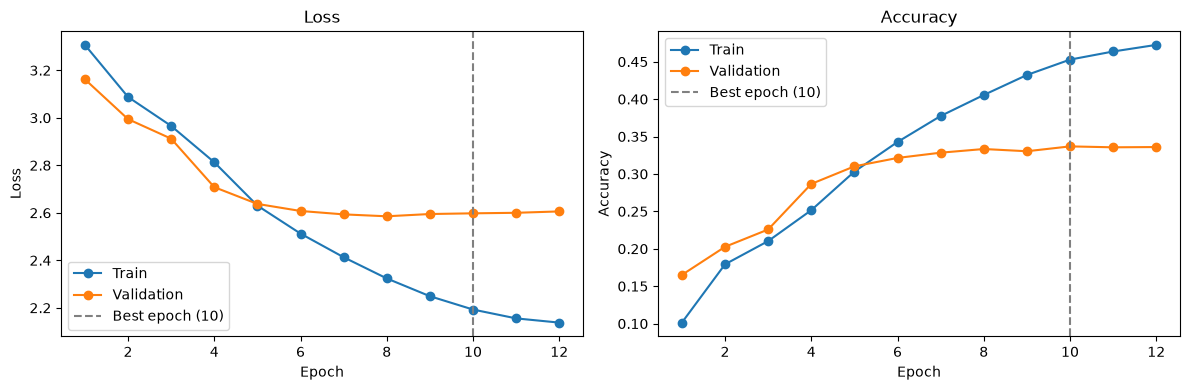

In [34]:
def plot_history(ckpt):
    with open(history_path(ckpt)) as f:
        h = json.load(f)
    epochs = range(1, len(h["val_acc"]) + 1)
    best_epoch = int(np.argmax(h["val_acc"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, title in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy")]:
        ax.plot(epochs, h[f"train_{key}"], marker="o", label="Train")
        ax.plot(epochs, h[f"val_{key}"], marker="o", label="Validation")
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.legend()
    plt.tight_layout()
    plt.savefig(ckpt.replace(".pt", "_curves.png"), dpi=200)
    plt.show()

plot_history(FINAL)

From the graph above, at epoch 10, training error is ~55% and validation error ~66%, so the model suffers from both high bias (poor fit even on training data) and high variance (an ~11-point generalization gap). Validation loss bottoms at epoch 8 while accuracy peaks at epoch 10. The ~3.3 starting loss suggests 30+ classes, so errors likely cluster in confusable or underrepresented classes.

In [40]:
net = build(coord_stages=(3, 4, 5, 6))
net.load_state_dict(torch.load(FINAL, map_location=device))
net.to(device).eval()

preds, targets = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds.append(net(x).argmax(1).cpu())
        targets.append(y.cpu())
preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()

print("test accuracy:", accuracy_score(targets, preds))
print("test macro F1:", f1_score(targets, preds, average="macro"))
print(classification_report(targets, preds, digits=3))

pretrained backbone loaded; skipped 0 tensors []
test accuracy: 0.31333333333333335
test macro F1: 0.3044491620504486
              precision    recall  f1-score   support

           0      0.183     0.137     0.157       190
           1      0.257     0.284     0.270       190
           2      0.167     0.205     0.184       190
           3      0.450     0.521     0.483       190
           4      0.373     0.442     0.405       190
           5      0.494     0.663     0.566       190
           6      0.421     0.447     0.434       190
           7      0.582     0.579     0.580       190
           8      0.345     0.358     0.351       190
           9      0.175     0.163     0.169       190
          10      0.386     0.337     0.360       190
          11      0.207     0.126     0.157       190
          12      0.175     0.253     0.207       190
          13      0.226     0.126     0.162       190
          14      0.239     0.289     0.262       190
          15     

Test accuracy is 31.3% and macro F1-score is 0.304, only slightly below validation (~34%) and far above the 3.3% chance level, so the model learned a real but weak signal. 

Strong classes: 28, 7, 5, 22 (F1 > 0.55). 

Weakest: 15, 19, 23, 27, 0, 11, 13 (F1 < 0.17), mostly with low recall

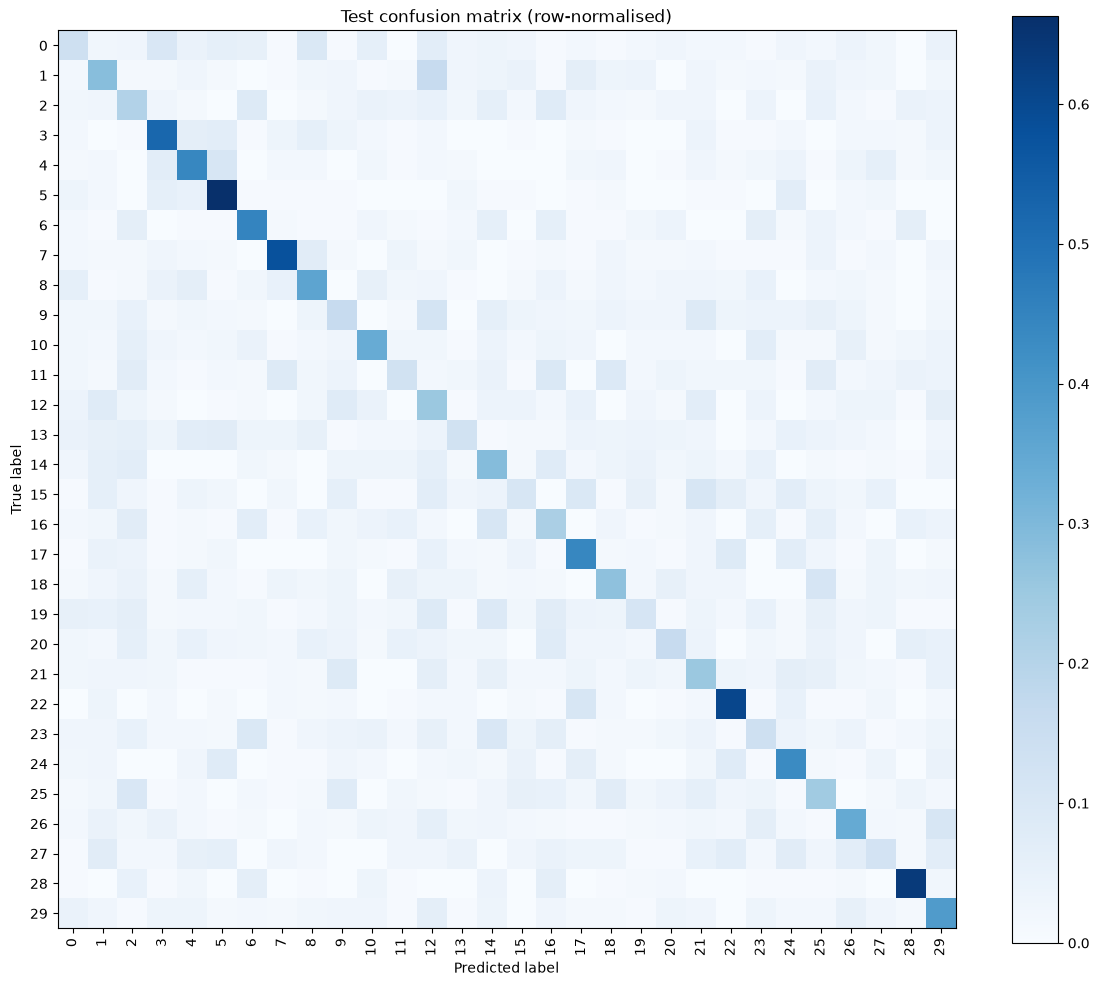

true 1 -> predicted 12: 31 (16% of class)
true 9 -> predicted 12: 22 (12% of class)
true 18 -> predicted 25: 21 (11% of class)
true 26 -> predicted 29: 20 (11% of class)
true 4 -> predicted 5: 20 (11% of class)
true 16 -> predicted 14: 20 (11% of class)
true 22 -> predicted 17: 20 (11% of class)
true 15 -> predicted 21: 20 (11% of class)
true 25 -> predicted 2: 19 (10% of class)
true 0 -> predicted 3: 19 (10% of class)


In [41]:
cm = confusion_matrix(targets, preds, labels=range(num_classes), normalize="true")

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", include_values=False, xticks_rotation=90)
ax.set_title("Test confusion matrix (row-normalised)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

counts = confusion_matrix(targets, preds, labels=range(num_classes))
np.fill_diagonal(counts, 0)
for k in counts.ravel().argsort()[::-1][:10]:
    t, p = divmod(int(k), num_classes)
    print(f"true {classes[t]} -> predicted {classes[p]}: {counts[t, p]} ({cm[t, p]:.0%} of class)")

The confusion matrix shows a clear diagonal, but errors are diffuse rather than concentrated, which can be due to shee amount of classes. Classes 5, 28, 22, 3, and 7 are strongest (0.5 to 0.65 recall). Weak classes (0, 9, 11, 13, 15, 19, 23, 27) have faint diagonals, with errors spread thinly across many classes rather than one dominant confusion. A few mild patterns appear: 1 → 12, 9 → 12, 13 → 14, 16 → 14, and 22 → 17. Class 12 and 14 act as attractor classes, absorbing predictions from several others.

## Model Improvement

To improve the classification performance, an ensemble model is created by integrating the CNN model to get the visual information with an OCR and BERT-based model to get the textual information. This approach combines visual and textual information from books to capture more features

## OCR

Setup the necessary libraries and paths to be used for OCR

In [39]:
CSV_IN = "dataset_updated/train/listings_train.csv"
FOLDER = "dataset_updated/224x224"
USE_GPU = torch.cuda.is_available()

In [40]:
reader = easyocr.Reader(["en"], gpu=USE_GPU)

The function below is used to clean up the data obtained from the OCR

In [41]:
def clean_ocr_text(text, max_chars=300):
    text = str(text)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    text = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", text)
    text = re.sub(r"(?<=[A-Za-z])(?=\d)|(?<=\d)(?=[A-Za-z])", " ", text)
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s.,&':-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = []
    for tok in text.split():
        core = tok.strip(".,&':-")
        if not core:
            continue
        if len(core) == 1 and core not in {"a", "i", "&"} and not core.isdigit():
            continue
        if tokens and tokens[-1] == tok:
            continue
        tokens.append(tok)
    return " ".join(tokens)[:max_chars].strip()

The images are processed in batches

In [42]:
def _postprocess(results, min_conf):
    results = sorted(results, key=lambda r: (min(pt[1] for pt in r[0]), min(pt[0] for pt in r[0])))
    seen, uniq = set(), []
    for _, txt, conf in results:
        txt = txt.strip()
        key = txt.lower()
        if conf < min_conf or not txt or key in seen:
            continue
        seen.add(key)
        uniq.append(txt)
    return " ".join(uniq)

In [43]:
def easyocr_ocr(paths, min_conf=0.2, mag_ratio=2.0, batch_size=16, rec_batch_size=32):
    raw = []
    for i in tqdm(range(0, len(paths), batch_size), desc="EasyOCR (batched)"):
        chunk = paths[i:i + batch_size]
        try:
            imgs = [np.array(Image.open(p).convert("RGB")) for p in chunk]
            batch_results = reader.readtext_batched(imgs, n_width=224, n_height=224, batch_size=rec_batch_size, 
                mag_ratio=mag_ratio, detail=1,)
            raw.extend(_postprocess(res, min_conf) for res in batch_results)
        except Exception as e:
            print(f"Batch {i // batch_size} failed ({e}); falling back to single images")
            for p in chunk:
                try:
                    res = reader.readtext(p, detail=1, mag_ratio=mag_ratio, batch_size=rec_batch_size)
                    raw.append(_postprocess(res, min_conf))
                except Exception as e2:
                    print(f"OCR failed on {p}: {e2}")
                    raw.append("")
    return raw

EasyOCR is used as the OCR library (Mahajan, 2023)

In [ ]:
def run_ocr(csv_in=CSV_IN, sample_size=None, seed=42, save_to="dataset_updated/train/train_ocr_easyocr.csv"):
    if os.path.exists(save_to):
        print(f"File already exists. Skipping OCR: {save_to}")
        return pd.read_csv(save_to, keep_default_na=False)

    df = pd.read_csv(csv_in, keep_default_na=False)

    if sample_size is not None:
        df = df.sample(n=min(sample_size, len(df)), random_state=seed)
    df = df.reset_index(drop=True)

    paths = [os.path.join(FOLDER, f) for f in df["filename"].astype(str)]
    missing = [p for p in paths if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(f"{len(missing)} images not found, e.g. {missing[0]}")

    df["ocr_raw"] = easyocr_ocr(paths)
    df["ocr_text"] = df["ocr_raw"].map(clean_ocr_text)

    def word_overlap(ocr, title):
        o = set(ocr.split())
        t = set(clean_ocr_text(title).split())
        return len(o & t) / len(o) if o else 0.0

    df["ocr_title_overlap"] = [word_overlap(o, t) for o, t in zip(df["ocr_text"], df["title"])]

    print(f"\nInput CSV:             {csv_in}")
    print(f"Total images:          {len(df)}")
    print(f"With OCR text:         {(df['ocr_text'].str.len() > 0).mean():.1%}")
    print(f"Avg chars per cover:   {df['ocr_text'].str.len().mean():.1f}")
    print(f"Avg word overlap:      {df['ocr_title_overlap'].mean():.2f}")
    print(f"Overlap >= 0.5:        {(df['ocr_title_overlap'] >= 0.5).mean():.1%}")

    os.makedirs(os.path.dirname(save_to) or ".", exist_ok=True)
    df.to_csv(save_to, index=False)
    print(f"Saved to: {save_to}")

OCR is ran on the train, testing, and validation set

In [45]:
run_ocr(csv_in="dataset_updated/train/listings_train.csv", sample_size=None, save_to="dataset_updated/train/train_easy_ocr.csv")

File already exists. Skipping OCR: dataset_updated/train/train_easy_ocr.csv


,filename,amazon_index_asin,image_url,title,author,category_id,category,ocr_raw,ocr_text,ocr_title_overlap
0,151721470X.jpg,151721470X,http://ecx.images-amazon.com/images/I/51odNH7g...,Sacked (A Gridiron Novel) (Volume 1),Jen Frederick,22,Romance,SAcKED CK JEN FREDER,sac ked ck jen freder,0.000000
1,0373779593.jpg,373779593,http://ecx.images-amazon.com/images/I/51d5Twwc...,Part Time Cowboy (Copper Ridge),Maisey Yates,22,Romance,MAISEY YATES Cant Slime cowboy,maisey yates cant slime cowboy,0.200000
2,0812982134.jpg,812982134,http://ecx.images-amazon.com/images/I/51u4iUuK...,The Money Class: How to Stand in Your Truth an...,Suze Orman,2,Business & Money,SUZE ORMAN Howt0#and In Your Truth And You Dui...,suze orman howt 0 and in your truth and you du...,0.461538
3,1742707726.jpg,1742707726,http://ecx.images-amazon.com/images/I/5194GlvM...,Decorated: Sublimely Crafted Cakes for Every O...,April Carter,7,"Cookbooks, Food & Wine",DECORATED WML,decorated wml,0.000000
4,900428365X.jpg,900428365X,http://ecx.images-amazon.com/images/I/51bcn6cv...,A Student's Dictionary of Classical and Mediev...,Paul W. Kroll,20,Reference,Students Dictionary of Classical and Medieval ...,students dictionary of classical and medieval ...,0.857143
...,...,...,...,...,...,...,...,...,...,...
45588,1599213486.jpg,1599213486,http://ecx.images-amazon.com/images/I/51tqZACg...,Book of Sailing Knots: How To Tie And Correctl...,Peter Owen,10,Engineering & Transportation,T h € B 0 0 k Sailing Knots Ho,0 sailing knots ho,0.500000
45589,147018138X.jpg,147018138X,http://ecx.images-amazon.com/images/I/41GbG3xm...,Lies & Myths About Corporate Wellness,Greg Justice,11,"Health, Fitness & Dieting",Greg Jusllco CORPORATE WELLNESS,greg jusllco corporate wellness,0.500000
45590,193324108X.jpg,193324108X,http://ecx.images-amazon.com/images/I/51CeVTOx...,Numbers 1-30 Write & Wipe Flash Cards (Kumon F...,Kumon Publishing North America,28,Test Preparation,Kumon Flash Cards NUMBERS1-30 WRITE AND WIPE! ...,kumon flash cards numbers 1-30 write and wipe ...,0.636364
45591,077831829X.jpg,077831829X,http://ecx.images-amazon.com/images/I/51ZR6Wvs...,Trading Christmas: The Forgetful Bride,Debbie Macomber,22,Romance,DEBBIE MACOMBER Trading Christmas,debbie macomber trading christmas,0.250000


In [46]:
run_ocr(csv_in="dataset_updated/validation/listings_val.csv", sample_size=None, save_to="dataset_updated/validation/val_easy_ocr.csv")

File already exists. Skipping OCR: dataset_updated/validation/val_easy_ocr.csv


,filename,amazon_index_asin,image_url,title,author,category_id,category,ocr_raw,ocr_text,ocr_title_overlap
0,0544279328.jpg,544279328,http://ecx.images-amazon.com/images/I/51L6RyF-...,How to Raise a Wild Child: The Art and Science...,Scott D. Sampson,18,Parenting & Relationships,HOw To Rarse WILD CHIID scott D- SAMPSON,how to rarse wild chiid scott sampson,0.428571
1,0801887186.jpg,801887186,http://ecx.images-amazon.com/images/I/41%2BTy8...,Senior Living Communities: Operations Manageme...,Benjamin W. Pearce,18,Parenting & Relationships,Senior Living Communities,senior living communities,1.000000
2,1634594525.jpg,1634594525,http://ecx.images-amazon.com/images/I/51mSHfYp...,"Big Data, Big Challenges in Evidence-Based Pol...",H. Kumar Jayasuriya,6,Computers & Technology,,,0.000000
3,0872204022.jpg,872204022,http://ecx.images-amazon.com/images/I/41ZxBTc-...,Dialogues Concerning Natural Religion (Hackett...,David Hume,25,Self-Help,David Hume Dialogues Concerning Religion Natural,david hume dialogues concerning religion natural,0.666667
4,0962781037.jpg,962781037,http://ecx.images-amazon.com/images/I/41fATP0q...,Delightful Vietnamese Cooking,Eng Tie Ang,7,"Cookbooks, Food & Wine",Delightful Vietnamese Cooking Ana; Ena Tio,delightful vietnamese cooking ana ena tio,0.500000
...,...,...,...,...,...,...,...,...,...,...
5695,1586489534.jpg,1586489534,http://ecx.images-amazon.com/images/I/51PVt6XI...,"Power Hungry: The Myths of ""Green"" Energy and ...",Robert Bryce,2,Business & Money,POwER HUNGRY,pow er hungry,0.000000
5696,0880113146.jpg,880113146,http://ecx.images-amazon.com/images/I/7199N441...,Hockey Fitness: Year-Round Conditioning on and...,Don MacAdams,26,Sports & Outdoors,Hockev Eitness Conditioning On and Off the Ice...,hockev eitness conditioning on and off the ice...,0.461538
5697,B004RSFXUI.jpg,B004RSFXUI,http://ecx.images-amazon.com/images/I/51TqZaTj...,Bobby Jones on Golf 1966 1st Edition,Robert Tyre (Bobby) Jones,26,Sports & Outdoors,BOBBY 8 JONES ON GOLF 1 3,bobby 8 jones on golf 1 3,0.714286
5698,0805099247.jpg,805099247,http://ecx.images-amazon.com/images/I/51djtVnr...,The Heart of Betrayal (The Remnant Chronicles),Mary E. Pearson,27,Teen & Young Adult,HEART THE OF BETRAYAL,heart the of betrayal,1.000000


In [47]:
run_ocr(csv_in="dataset_updated/test/listings_test.csv", sample_size=None, save_to="dataset_updated/test/test_easy_ocr.csv")

File already exists. Skipping OCR: dataset_updated/test/test_easy_ocr.csv


,filename,amazon_index_asin,image_url,title,author,category_id,category,ocr_raw,ocr_text,ocr_title_overlap
0,044310073X.jpg,044310073X,http://ecx.images-amazon.com/images/I/41kSLEos...,Oral and Maxillofacial Surgery: An Objective-B...,,16,Medical Books,Oral amri Maxillofacial Surgery JJunatham Pediar,oral amri maxillofacial surgery jjunatham pediar,0.333333
1,1438005687.jpg,1438005687,http://ecx.images-amazon.com/images/I/510l0qhi...,"Barron's GRE, 21st Edition",Sharon Weiner Green M.A.,28,Test Preparation,BARRONS Thic Lcadcr in Tcst Preparitlon GRE,barrons thic lcadcr in tcst preparitlon gre,0.000000
2,0060750715.jpg,60750715,http://ecx.images-amazon.com/images/I/51p5aUY%...,George Balanchine: The Ballet Maker (Eminent L...,Robert Gottlieb,1,Biographies & Memoirs,Ballet The Maker George Balanchine Robert Gott...,ballet the maker george balanchine robert gott...,0.571429
3,1580237959.jpg,1580237959,http://ecx.images-amazon.com/images/I/51pum0eW...,"A Partner in Holiness: Deepening Mindfulness, ...",Rabbi Jonathan P. Slater DMin,21,Religion & Spirituality,PARTNER in HOLINESS YOLUAI ? Lotiticul Numban ...,partner in holiness yoluai lotiticul numban de...,0.608696
4,0135137829.jpg,135137829,http://ecx.images-amazon.com/images/I/51PuTPPC...,Construction Scheduling: Principles and Practi...,Jay S. Newitt,0,Arts & Photography,Construction Scheduling,construction scheduling,0.500000
...,...,...,...,...,...,...,...,...,...,...
5695,0399174680.jpg,399174680,http://ecx.images-amazon.com/images/I/51JLVnuX...,Scandalous Behavior (A Stone Barrington Novel),Stuart Woods,17,"Mystery, Thriller & Suspense",STUART WOODS SCANDALOUS BEHAVIOR,stuart woods scandalous behavior,0.500000
5696,1939454654.jpg,1939454654,http://ecx.images-amazon.com/images/I/417gaArF...,Age of Distraction: The Island,Patricia Mahon,17,"Mystery, Thriller & Suspense",The Age Of DISTRacTion TME ISLAN PAtrIHIa MAHON,the age of distrac tion tme islan patr ihia mahon,0.300000
5697,1604601604.jpg,1604601604,http://ecx.images-amazon.com/images/I/51BJw1DW...,The Ghostly Quilts on Main (Colebridge Communi...,Ann Hazelwood,17,"Mystery, Thriller & Suspense",GHOSTLY QUILTS Mein AWl,ghostly quilts mein awl,0.500000
5698,0399166726.jpg,399166726,http://ecx.images-amazon.com/images/I/51IQRzWX...,Saving Jason (A Jason Stafford Novel),Michael Sears,17,"Mystery, Thriller & Suspense","Saving ""Jason MICHAEL SEARS",saving jason michael sears,0.500000


## CNN with OCR + BERT

##### To train the CNN with OCR + BERT model, a new function is used such that the output is the filename and the OCR text obtained earlier (Pytorch Contributors, 2026).

In [48]:
class MultimodalDataset(Dataset):
    def __init__(self, folder, csv_path, size=(224, 224), mean=None, std=None, label_map=None):
        df = pd.read_csv(csv_path)
        self.files = df["filename"].astype(str).tolist()
        self.ocr = df["ocr_text"].fillna("").astype(str).tolist() if "ocr_text" in df.columns else [""] * len(df)
        raw = df["category_id"].tolist()

        self.label_map = label_map or {c: i for i, c in enumerate(sorted(set(raw)))}
        self.labels = [self.label_map[c] for c in raw]

        self.folder, self.size = folder, size
        self.normalize = mean is not None and std is not None
        if self.normalize:
            self.mean = torch.as_tensor(mean, dtype=torch.float32).view(3, 1, 1)
            self.std = torch.as_tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = os.path.join(self.folder, self.files[idx])
        img = cv2.imread(path)
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, self.size, interpolation=cv2.INTER_AREA)
        img = torch.from_numpy(img).permute(2, 0, 1).float().div_(255.0)
        if self.normalize:
            img = (img - self.mean) / self.std
        return (img, 
                self.ocr[idx], 
                self.labels[idx])

Both the image and text requires a collate function (Pytorch Contributors, 2023; Pytorch Forums, n.d.).

In [ ]:
from torch.utils.data._utils.collate import collate_tensor_fn, collate_int_fn
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def multimodal_collate(batch):
    images, ocr_texts, labels = zip(*batch)
    image_data = collate_tensor_fn(images)
    label_data = collate_int_fn(labels)

    text_data = tokenizer(list(ocr_texts), padding=True, truncation=True, max_length=128, return_tensors="pt")

    return image_data, text_data, label_data
    

The model combines image and text features through multimodal learning. It uses the CNN model to extract visual features from input images and a pretrained BERT model to extract contextual text features. Both models can optionally be frozen to prevent their weights from updating during training. The extracted image features and BERT's [CLS] token representation are concatenated into a single feature vector. This combined representation is passed through a fully connected classifier with GELU activation and dropout to predict the final class (Alammar, n.d.;BERT - Hugging Face, n.d.; Tutorial: Adding a model - Concat BERT | MMF; 2021).

In [50]:
class CoverNetText(nn.Module):
    def __init__(self, model, img_dim, num_classes,
                 bert_name="bert-base-uncased", hidden=512, dropout=0.3,
                 freeze_image=True, freeze_bert=False):
        super().__init__()
        self.model = model
        self.bert = AutoModel.from_pretrained(bert_name)
        txt_dim = self.bert.config.hidden_size

        if freeze_image:
            for p in self.model.parameters():
                p.requires_grad = False
        if freeze_bert:
            for p in self.bert.parameters():
                p.requires_grad = False

        self.classifier = nn.Sequential(
            nn.Linear(img_dim + txt_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, image, input_ids, attention_mask):
        img_x = self.model(image)                       
        txt_tokens = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        txt_x = txt_tokens.last_hidden_state[:, 0, :]                      
        return self.classifier(torch.cat([img_x, txt_x], dim=1))

Call the CNN model from early and use the weights from its best results from the hyperparameter tuning

In [51]:
covernet = CoverNet(num_classes=30, coord_stages=(3, 4, 5, 6), large_kernel=3, 
                    color_gate_stage=None, head_attn=False, head_zones=0)
covernet.head = PlainHead(num_classes=30)    

state_dict = torch.load("best_model.pt", map_location="cpu", weights_only=True)
covernet.load_state_dict(state_dict)

<All keys matched successfully>

In [52]:
covernet.head.fc = nn.Identity()
covernet = covernet.to(device)

In [53]:
for param in covernet.parameters():
    param.requires_grad = False

covernet.eval()

CoverNet(
  (features): Sequential(
    (0): Conv2dNormAct(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (norm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): MBConv(
      (block): Sequential(
        (0): Identity()
        (1): Conv2dNormAct(
          (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (norm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (2): SqueezeExcitation(
          (block): Sequential(
            (0): AdaptiveAvgPool2d(output_size=1)
            (1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (2): SiLU(inplace=True)
            (3): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (4): Sigmoid()
          )
        )
        (3): Conv2

Call the multimodal model

In [54]:
fusion_model = CoverNetText(model=covernet, img_dim=1280, num_classes=30, freeze_image=True, freeze_bert=False).to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Setup the data loaders for the train and validation set. The mean and standard deviation is from ImageNet

In [56]:
mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
std  = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)

train_ds = MultimodalDataset("dataset_updated/224x224", "dataset_updated/train/train_easy_ocr.csv", mean=mean.to("cpu"), std=std.to("cpu"))
valid_ds = MultimodalDataset("dataset_updated/224x224", "dataset_updated/validation/val_easy_ocr.csv", mean=mean.to("cpu"), std=std.to("cpu"))

BATCH_SIZE = 256
NUM_WORKERS = 3

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=True, collate_fn=multimodal_collate)
val_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=False, collate_fn=multimodal_collate)

In [57]:
title = "fusion_frozen_covernet"

os.makedirs("fusion_logs_final", exist_ok=True)

train_log_path = f"fusion_logs_final/train_{title}_logs.csv"
val_log_path = f"fusion_logs_final/val_{title}_logs.csv"

Set the criterion, optimizer, and scaler

In [58]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(fusion_model.parameters(), lr=1e-4)

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

Set the per epoch training

In [59]:
def train_one_epoch(epoch_index, title="fusion"):
    fusion_model.train()

    total_loss, correct_top1, correct_top3, total = 0.0, 0, 0, 0

    for batch in train_loader:
        images, text_data, labels = batch
        
        images = images.to(device)
        input_ids = text_data["input_ids"].to(device)
        attention_mask = text_data["attention_mask"].to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type,enabled=(device.type == "cuda")):
            outputs = fusion_model(images, input_ids, attention_mask)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        _, predicted = torch.topk(outputs, k=3, dim=1)

        correct_top1 += (predicted[:, 0] == labels).sum().item()
        correct_top3 += predicted.eq(labels.view(-1, 1)).any(dim=1).sum().item()

        total += batch_size

    avg_loss = total_loss / total
    top1_acc = 100 * correct_top1 / total
    top3_acc = 100 * correct_top3 / total

    with open(train_log_path, "a", newline="") as file:
        csv_writer = csv.writer(file)
        csv_writer.writerow([epoch_index + 1, avg_loss, top1_acc, top3_acc])

    return avg_loss, top1_acc, top3_acc

In [60]:
def validate_one_epoch():
    fusion_model.eval()
    running_vloss, correct_top1, correct_top3, total = 0.0, 0, 0, 0
    with torch.no_grad():
        for i, batch in enumerate(val_loader):
            images, text_data, labels = batch
            images = images.to(device)
            input_ids = text_data["input_ids"].to(device)
            attention_mask = text_data["attention_mask"].to(device)
            labels = labels.to(device)
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = fusion_model(images, input_ids, attention_mask)
                loss = criterion(outputs, labels)
            batch_size = labels.size(0)
            running_vloss += loss.item() * batch_size
            _, predicted = torch.topk(outputs, k=3, dim=1)
            correct_top1 += (predicted[:, 0] == labels).sum().item()
            correct_top3 += predicted.eq(labels.view(-1, 1)).any(dim=1).sum().item()
            total += batch_size
    return running_vloss / total, 100 * correct_top1 / total, 100 * correct_top3 / total, i + 1

In [67]:
def train_network(epochs, title="fusion", patience=3):
    epoch_number, best_loss, bad_epochs = 0, float("inf"), 0
    print("=" * 65)
    for epoch in range(epochs):
        print(f"EPOCH {epoch_number + 1}:")
        start_time = time.time()
        train_avg_loss, train_top1_accuracy, train_top3_accuracy = train_one_epoch(epoch_number, title)
        print(f"Training Time: {time.time() - start_time:.4f}s")
        val_avg_loss, val_top1_acc, val_top3_acc, num_batches = validate_one_epoch()
        print("-" * 48)
        print(f"{'Statistic':<15}{'Train':>12}{'Validation':>15}")
        print("-" * 48)
        print(f"{'Loss':<15}{train_avg_loss:>12.4f}{val_avg_loss:>15.4f}")
        print(f"{'Top-1 Accuracy':<15}{train_top1_accuracy:>11.2f}%{val_top1_acc:>14.2f}%")
        print(f"{'Top-3 Accuracy':<15}{train_top3_accuracy:>11.2f}%{val_top3_acc:>14.2f}%")
        print("=" * 65)
        with open(val_log_path, "a", newline="") as file:
            csv_writer = csv.writer(file)
            csv_writer.writerow([epoch_number + 1, num_batches, val_avg_loss, val_top1_acc, val_top3_acc])
        if val_avg_loss < best_loss:
            best_loss, bad_epochs = val_avg_loss, 0
            model_path = f"fusion_logs_final/model_{epoch_number + 1}.pt"
            torch.save({"model": fusion_model.state_dict(), "label_map": train_ds.label_map, "epoch": epoch_number + 1,
                        "val_loss": val_avg_loss, "val_top1_acc": val_top1_acc, "val_top3_acc": val_top3_acc}, model_path)
            print(f"Best model saved: {model_path}")
        else:
            bad_epochs += 1
            print(f"No improvement for {bad_epochs}/{patience} epochs")
            if bad_epochs >= patience: print("Early stopping."); break
        epoch_number += 1

Train the model in 30 epochs and if model does not improve in 3 epochs, it would go to an early stop

In [68]:
train_network(epochs=30, title="fusion_frozen_covernet", patience=3)

EPOCH 1:
Training Time: 143.2130s
------------------------------------------------
Statistic             Train     Validation
------------------------------------------------
Loss                 0.2880         2.7503
Top-1 Accuracy       91.81%         47.04%
Top-3 Accuracy       97.28%         66.07%
Best model saved: fusion_logs_final/model_1.pt
EPOCH 2:
Training Time: 143.0909s
------------------------------------------------
Statistic             Train     Validation
------------------------------------------------
Loss                 0.2319         2.8800
Top-1 Accuracy       93.31%         47.21%
Top-3 Accuracy       97.72%         65.40%
No improvement for 1/3 epochs
EPOCH 3:
Training Time: 154.2293s
------------------------------------------------
Statistic             Train     Validation
------------------------------------------------
Loss                 0.2076         3.0052
Top-1 Accuracy       94.06%         46.65%
Top-3 Accuracy       97.87%         65.44%
No improvem

Prepare the test set for evaluation

In [69]:
test_ds = MultimodalDataset("dataset_updated/224x224", "dataset_updated/test/test_easy_ocr.csv", mean=mean.to("cpu"), std=std.to("cpu"))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=False, collate_fn=multimodal_collate)

Use the latest best model

In [72]:
paths = glob.glob("fusion_logs_final/model_*.pt")
latest = max(paths, key=lambda p: int(re.search(r"model_(\d+)\.pt", p).group(1)))

ckpt = torch.load(latest, map_location=device)
fusion_model.load_state_dict(ckpt["model"])
print("loaded:", latest, "| epoch", ckpt["epoch"], "| val loss", round(ckpt["val_loss"], 4),
      "| val acc", ckpt["val_top1_acc"])

loaded: fusion_logs_final/model_1.pt | epoch 1 | val loss 2.7503 | val acc 47.03508771929825


Train the test set to the model

In [73]:
def test_model(loader, label_map):
    fusion_model.eval()
    correct_top1, correct_top3, total, loss_sum = 0, 0, 0, 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, text_data, labels in loader:
            images, labels = images.to(device), labels.to(device)
            input_ids = text_data["input_ids"].to(device)
            attention_mask = text_data["attention_mask"].to(device)
            outputs = fusion_model(images, input_ids, attention_mask)
            loss_sum += criterion(outputs, labels).item() * labels.size(0)
            top3 = torch.topk(outputs, k=3, dim=1).indices
            correct_top1 += (top3[:, 0] == labels).sum().item()
            correct_top3 += top3.eq(labels.view(-1, 1)).any(dim=1).sum().item()
            total += labels.size(0)
            all_preds += top3[:, 0].cpu().tolist()
            all_labels += labels.cpu().tolist()

    print(f"Test loss: {loss_sum/total:.4f} | Top-1: {100*correct_top1/total:.2f}% | Top-3: {100*correct_top3/total:.2f}%")
    print(f"Macro F1: {f1_score(all_labels, all_preds, average='macro', zero_division=0):.4f}\n")

    inv_map = {v: k for k, v in label_map.items()}
    idx = list(range(len(inv_map)))
    names = [str(inv_map[i]) for i in idx]
    print(classification_report(all_labels, all_preds, labels=idx,
                                target_names=names, zero_division=0, digits=4))
    return all_labels, all_preds

y_true, y_pred = test_model(test_loader, train_ds.label_map)

Test loss: 2.8460 | Top-1: 44.61% | Top-3: 65.26%
Macro F1: 0.4479

              precision    recall  f1-score   support

           0     0.3221    0.2526    0.2832       190
           1     0.2353    0.3158    0.2697       190
           2     0.3440    0.5105    0.4110       190
           3     0.6561    0.6526    0.6544       190
           4     0.4599    0.3316    0.3853       190
           5     0.5350    0.6842    0.6005       190
           6     0.7143    0.6579    0.6849       190
           7     0.7377    0.7105    0.7239       190
           8     0.4906    0.4105    0.4470       190
           9     0.3184    0.3000    0.3089       190
          10     0.5357    0.4737    0.5028       190
          11     0.4286    0.4105    0.4194       190
          12     0.3036    0.3947    0.3432       190
          13     0.3413    0.3000    0.3193       190
          14     0.4813    0.4737    0.4775       190
          15     0.3469    0.1789    0.2361       190
          16 

The multimodal model achieved 44.61% Top-1 accuracy, 65.26% Top-3 accuracy, and a 44.79% Macro F1-score on the test dataset. Class 28 achieved the highest F1-score (79.48%), followed by classes 7 (72.39%) and 6 (68.49%). However, classes 19, 27, and 15 showed weaker performance, suggesting difficulty distinguishing these categories. 

## Model Performance Summary

![Model Performance Summary](model_summary.png)

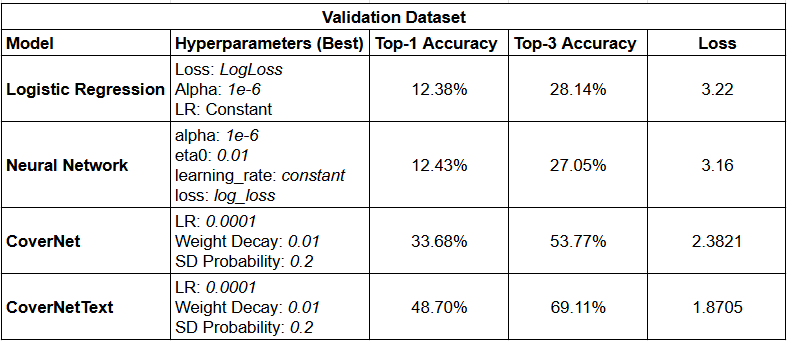

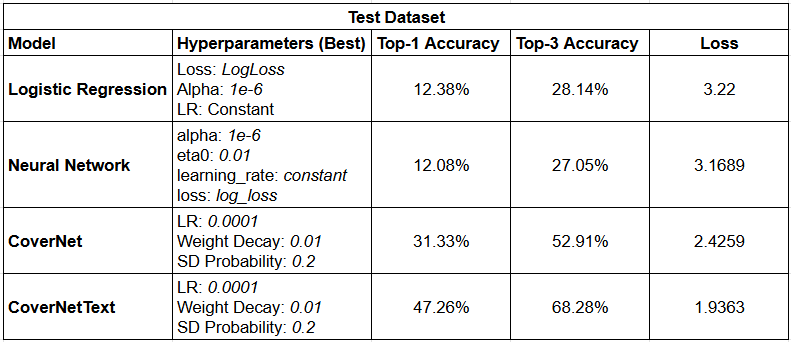

The tables above show the chosen models and a comparison of their hyperparameters, accuracy (top-1 and top-3) and loss on the training, validation and test sets. Throughout all the testing, the CoverNetText model shows the highest accuracy (*47.26%*, and *68.28%* in top-1 and top-3 accuracy respectively) and lowest loss (*1.9363*). 

The increase in accuracy between the original CoverNet and CoverNetText could be attributed to the addition of using the extracted text from the images as additional data to be trained upon. There is a significant increase in accuracy between the normal neural network and using a convolutional neural network indicating that convolutional neural networks are much more suited to image datasets.

## References

Alammar, J. (n.d.). A visual guide to using BERT for the first time. https://jalammar.github.io/a-visual-guide-to-using-bert-for-the-first-time/

BERT · Hugging face. (n.d.). https://huggingface.co/docs/transformers/v5.24.1/en/model_doc/bert?utm_source=chatgpt.com#transformers.BertModel

Braz, L., Teixeira, V., Pedrini, H., & Dias, Z. (2021). Image-text integration using a multimodal fusion network module for movie genre classification. IET Conference Proceedings, 2021(1), 200–205. https://doi.org/10.1049/icp.2021.1456

Brian Kenji Iwana, Rizvi,, Ahmed, S., Dengel, A., & Uchida, S. (2016). Judging a book by its cover. https://doi.org/10.48550/arxiv.1610.09204

Haraguchi, D., Iwana, B. K., & Uchida, S. (2024). What text design characterizes book genres? (arXiv:2402.16356). arXiv. https://doi.org/10.48550/arXiv.2402.16356


Mahajan, A. (2023, October 28). EasyOCR: A comprehensive guide. Medium. https://medium.com/@adityamahajan.work/easyocr-a-comprehensive-guide-5ff1cb850168

Perez, E., Strub, F., de Vries, H., Dumoulin, V., & Courville, A. (2018). FiLM: Visual Reasoning with a General Conditioning Layer. Proceedings of the AAAI Conference on Artificial Intelligence, 32(1). https://doi.org/10.1609/aaai.v32i1.11671

PyTorch Contributors. (2026). pytorch/torch/utils/data/_utils/collate.py (Version 2.15.0) [Source code]. GitHub. https://github.com/pytorch/pytorch/blob/v2.15.0/torch/utils/data/_utils/collate.py#L340

PyTorch Contributors. (2023, January 1). DataLoader. https://docs.pytorch.org/cppdocs/api/data/dataloader.html
How to use collate_fn(). (2018, October 13). 

PyTorch Contributors. (2026, May 7). torch.utils.data — PyTorch 2.15 documentation. PyTorch. https://docs.pytorch.org/docs/2.15/data.html#torch.utils.data.IterableDataset


PyTorch Forums. (n.d.). https://discuss.pytorch.org/t/how-to-use-collate-fn/27181

pytorch/torch/utils/data/_utils/collate.py at v2.15.0 · pytorch/pytorch. (n.d.). GitHub. https://github.com/pytorch/pytorch/blob/v2.15.0/torch/utils/data/_utils/collate.py#L340

Seo, I. J., Lee, Y. H., & Jang, B. (2025). Classification of fashion e-commerce products using ResNet-BERT multi-modal deep learning and transfer learning optimization. Plos one, 20(5), e0324621.

Torch Contributors. (n.d.). EfficientNet — Torchvision main documentation. PyTorch. Retrieved November 27, 2026, from https://docs.pytorch.org/vision/main/models/efficientnet.html

Tutorial: Adding a model - Concat BERT | MMF. (2021, October 14). https://mmf.sh/docs/tutorials/concat_bert_tutorial/

## AI Usage

* Used Claude to bounce ideas for possible methods of improving the efficientnet model
* Used Claude to help troubleshoot integration errors of newer modules to customize efficientnet.
* Used Claude to optimize the codes and make it cleaner.
* Used ChatGPT to ask how to distribute memory with different GPU(s) due to Out of Memory Issues during training